# 📊 Phase 4: Exploratory Data Analysis (EDA) & Statistical Analysis
### UrbanFlow: Interactive Smart City Traffic & Accident Analytics

This notebook executes **Phase 4: Comprehensive Exploratory Data Analysis** strictly on the cleaned, analysis-ready dataset:
`Dataset/cleaned/urbanflow_cleaned.csv` (20,000 rows x 34 columns).

---
## Sections Included:
1. **STEP 4.1**: Load & Verify Clean Data
2. **STEP 4.2**: Core Analytical Summary Metrics
3. **STEP 4.3**: Temporal Dynamics (Year, Month, Day, Hour, Time Period, Weekday, Peak)
4. **STEP 4.4**: Accident Severity Breakdown
5. **STEP 4.5**: Root Causes & Pareto Analysis
6. **STEP 4.6**: City & State Incident Hotspots
7. **STEP 4.7**: Roadway Classifications, Lanes & Signal Control
8. **STEP 4.8**: Atmospheric Weather Conditions
9. **STEP 4.9**: Visibility Levels
10. **STEP 4.10**: Temperature Dynamics
11. **STEP 4.11**: Traffic Density Impact
12. **STEP 4.12**: Vehicles Involved vs. Casualties (Correlation Analysis)
13. **STEP 4.13 & 4.14**: Risk Score & Risk Category Analysis
14. **STEP 4.15 & 4.16**: Correlation Matrix & Statistical Relationships
15. **STEP 4.17**: Geographic Coordinate Spread
16. **STEP 4.20**: Automated Analysis Summary


### 1. Environment & Library Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import os

# Aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12

print("Libraries imported successfully.")


Libraries imported successfully.


### STEP 4.1: Load & Verify Cleaned Data

In [2]:
data_path = '../../Dataset/cleaned/urbanflow_cleaned.csv' if os.path.exists('../../Dataset/cleaned/urbanflow_cleaned.csv') else '../Dataset/cleaned/urbanflow_cleaned.csv'
if not os.path.exists(data_path):
    data_path = 'Dataset/cleaned/urbanflow_cleaned.csv'

df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])

print(f"Dataset successfully loaded from: {data_path}")
print(f"Row Count:    {df.shape[0]:,}")
print(f"Column Count: {df.shape[1]}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Missing Values (Non-Festival): {df.drop(columns=['festival']).isnull().sum().sum()}")


Dataset successfully loaded from: ../../Dataset/cleaned/urbanflow_cleaned.csv
Row Count:    20,000
Column Count: 34
Duplicate Rows: 0
Missing Values (Non-Festival): 0


### STEP 4.2: Initial EDA Summary Metrics

In [3]:
summary = {
    'Total Collisions': len(df),
    'Total Casualties': int(df['casualties'].sum()),
    'Total Vehicles Involved': int(df['vehicles_involved'].sum()),
    'Avg Casualties per Accident': df['casualties'].mean().round(3),
    'Avg Vehicles per Accident': df['vehicles_involved'].mean().round(3),
    'Mean Risk Score': df['risk_score'].mean().round(4),
    'Median Risk Score': df['risk_score'].median(),
    'Min Risk Score': df['risk_score'].min(),
    'Max Risk Score': df['risk_score'].max(),
    'Cities Represented': df['city'].nunique(),
    'States Represented': df['state'].nunique(),
    'Road Classifications': df['road_type'].nunique(),
    'Accident Causes': df['cause'].nunique(),
    'Weather Conditions': df['weather'].nunique(),
    'Severity Tiers': df['accident_severity'].nunique()
}

summary_df = pd.DataFrame(list(summary.items()), columns=['Metric', 'Value'])
display(summary_df)


,Metric,Value
0,Total Collisions,20000.0000
1,Total Casualties,34529.0000
2,Total Vehicles Involved,59840.0000
3,Avg Casualties per Accident,1.7260
4,Avg Vehicles per Accident,2.9920
5,Mean Risk Score,0.4376
6,Median Risk Score,0.4500
7,Min Risk Score,0.1000
8,Max Risk Score,1.0000
9,Cities Represented,8.0000


### STEP 4.3: Temporal Analysis (Year, Month, Day, Hour, Peak, Weekend)

In [4]:
# 1. Yearly Trend
print("--- ACCIDENTS BY YEAR ---")
yearly = df['year'].value_counts().sort_index()
display(pd.DataFrame({'Count': yearly, 'Share (%)': (yearly/len(df)*100).round(2)}))

# 2. Monthly Trend
print("--- TOP & BOTTOM MONTHS ---")
monthly = df['month_name'].value_counts()
print(f"Highest Month: {monthly.index[0]} ({monthly.iloc[0]:,} crashes)")
print(f"Lowest Month:  {monthly.index[-1]} ({monthly.iloc[-1]:,} crashes)")

# 3. Diurnal 24-Hour Cycle
hourly = df['hour'].value_counts().sort_values(ascending=False)
print(f"\nPeak Single Hour:   {hourly.index[0]}:00 ({hourly.iloc[0]:,} crashes)")
print(f"Lowest Single Hour: {hourly.index[-1]}:00 ({hourly.iloc[-1]:,} crashes)")

# 4. Time Period Breakdown
print("\n--- TIME PERIOD BREAKDOWN ---")
tp = df['time_period'].value_counts()
display(pd.DataFrame({'Count': tp, 'Share (%)': (tp/len(df)*100).round(2)}))

# 5. Weekend vs Weekday
print("--- WEEKEND VS WEEKDAY ---")
wk = df['is_weekend'].map({0: 'Weekday', 1: 'Weekend'}).value_counts()
display(pd.DataFrame({'Count': wk, 'Share (%)': (wk/len(df)*100).round(2)}))

# 6. Peak vs Non-Peak
print("--- PEAK VS NON-PEAK (8-10 AM, 5-7 PM) ---")
pk = df['is_peak_hour'].map({0: 'Non-Peak', 1: 'Peak Hour'}).value_counts()
pk_risk = df.groupby('is_peak_hour')['risk_score'].mean().round(4)
display(pd.DataFrame({'Count': pk, 'Share (%)': (pk/len(df)*100).round(2), 'Mean Risk': pk_risk.values}))


--- ACCIDENTS BY YEAR ---


,Count,Share (%)
year,,
2022,6117,30.58
2023,6088,30.44
2024,6061,30.30
2025,1734,8.67


--- TOP & BOTTOM MONTHS ---
Highest Month: January (2,044 crashes)
Lowest Month:  September (1,475 crashes)

Peak Single Hour:   2:00 (888 crashes)
Lowest Single Hour: 7:00 (786 crashes)

--- TIME PERIOD BREAKDOWN ---


,Count,Share (%)
time_period,,
Night,6721,33.61
Morning,4907,24.54
Evening,4192,20.96
Afternoon,4180,20.90


--- WEEKEND VS WEEKDAY ---


,Count,Share (%)
is_weekend,,
Weekday,14277,71.39
Weekend,5723,28.62


--- PEAK VS NON-PEAK (8-10 AM, 5-7 PM) ---


,Count,Share (%),Mean Risk
is_peak_hour,,,
Non-Peak,15052,75.26,0.3830
Peak Hour,4948,24.74,0.6038


### STEP 4.4: Accident Severity Dynamics

In [5]:
sev_df = df.groupby('accident_severity').agg(
    Count=('accident_id', 'count'),
    Avg_Casualties=('casualties', 'mean'),
    Avg_Risk=('risk_score', 'mean'),
    Avg_Vehicles=('vehicles_involved', 'mean')
).round(3)
sev_df['Share (%)'] = (sev_df['Count'] / len(df) * 100).round(2)
display(sev_df[['Count', 'Share (%)', 'Avg_Casualties', 'Avg_Risk', 'Avg_Vehicles']])


,Count,Share (%),Avg_Casualties,Avg_Risk,Avg_Vehicles
accident_severity,,,,,
fatal,2987,14.94,3.002,0.608,3.002
major,5988,29.94,1.495,0.407,2.972
minor,11025,55.12,1.507,0.408,3.000


### STEP 4.5: Root Cause & Pareto Analysis

In [6]:
cause_df = df.groupby('cause').agg(
    Count=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean'),
    Fatal_Count=('accident_severity', lambda x: (x == 'fatal').sum())
).sort_values('Count', ascending=False)
cause_df['Share (%)'] = (cause_df['Count'] / len(df) * 100).round(2)
cause_df['Fatal_Rate (%)'] = (cause_df['Fatal_Count'] / cause_df['Count'] * 100).round(2)
cause_df['Cumulative (%)'] = (cause_df['Count'].cumsum() / len(df) * 100).round(2)
display(cause_df)


,Count,Mean_Risk,Fatal_Count,Share (%),Fatal_Rate (%),Cumulative (%)
cause,,,,,,
distraction,4026,0.429297,542,20.13,13.46,20.13
overspeeding,4025,0.440186,603,20.12,14.98,40.26
weather,3997,0.439742,601,19.98,15.04,60.24
drunk driving,3978,0.438964,618,19.89,15.54,80.13
poor road,3974,0.439796,623,19.87,15.68,100.00


### STEP 4.6: Metropolitan City & State Analysis

In [7]:
city_df = df.groupby('city').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean'),
    Avg_Casualties=('casualties', 'mean'),
    High_Risk_Crashes=('risk_score', lambda x: (x >= 0.65).sum())
).sort_values('Total_Accidents', ascending=False)
city_df['Share (%)'] = (city_df['Total_Accidents'] / len(df) * 100).round(2)
display(city_df)

print("\n--- STATE-LEVEL AGGREGATIONS ---")
state_df = df.groupby('state').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean')
).sort_values('Total_Accidents', ascending=False)
state_df['Share (%)'] = (state_df['Total_Accidents'] / len(df) * 100).round(2)
display(state_df)


,Total_Accidents,Mean_Risk,Avg_Casualties,High_Risk_Crashes,Share (%)
city,,,,,
chandigarh,2577,0.441618,1.698487,616,12.88
chennai,2575,0.437573,1.773592,600,12.88
kolkata,2559,0.434584,1.761626,597,12.80
pune,2517,0.435836,1.755662,617,12.58
mumbai,2492,0.434350,1.724318,597,12.46
bangalore,2438,0.440217,1.693191,580,12.19
delhi,2433,0.437115,1.715988,609,12.16
hyderabad,2409,0.439456,1.684516,594,12.04



--- STATE-LEVEL AGGREGATIONS ---


,Total_Accidents,Mean_Risk,Share (%)
state,,,
maharashtra,5009,0.435097,25.04
punjab,2577,0.441618,12.88
tamil nadu,2575,0.437573,12.88
west bengal,2559,0.434584,12.80
karnataka,2438,0.440217,12.19
delhi,2433,0.437115,12.16
telangana,2409,0.439456,12.04


### STEP 4.7: Road Classification, Lanes & Signalization

In [8]:
road_df = df.groupby('road_type').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean'),
    Avg_Casualties=('casualties', 'mean'),
    Fatal_Rate=('accident_severity', lambda x: (x == 'fatal').mean() * 100)
).round(3)
display(road_df)

print("\n--- LANE COUNT IMPACT ---")
lane_df = df.groupby('lanes').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean'),
    Avg_Vehicles=('vehicles_involved', 'mean')
).round(3)
display(lane_df)


,Total_Accidents,Mean_Risk,Avg_Casualties,Fatal_Rate
road_type,,,,
highway,6616,0.437,1.726,14.858
rural,6639,0.435,1.722,14.535
urban,6745,0.441,1.732,15.404



--- LANE COUNT IMPACT ---


,Total_Accidents,Mean_Risk,Avg_Vehicles
lanes,,,
1,3382,0.439,2.996
2,3270,0.438,2.991
3,3334,0.435,2.972
4,3383,0.440,2.984
5,3363,0.435,3.021
6,3268,0.438,2.988


### STEP 4.8 & 4.9: Weather & Visibility Stressors

In [9]:
weath_df = df.groupby('weather').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean'),
    Avg_Casualties=('casualties', 'mean')
).round(3)
weath_df['Share (%)'] = (weath_df['Total_Accidents'] / len(df) * 100).round(2)
display(weath_df)

print("\n--- VISIBILITY ANALYSIS ---")
vis_df = df.groupby('visibility').agg(
    Total_Accidents=('accident_id', 'count'),
    Mean_Risk=('risk_score', 'mean')
).round(3)
display(vis_df)


,Total_Accidents,Mean_Risk,Avg_Casualties,Share (%)
weather,,,,
clear,6690,0.237,1.718,33.45
fog,6633,0.589,1.719,33.16
rain,6677,0.488,1.743,33.38



--- VISIBILITY ANALYSIS ---


,Total_Accidents,Mean_Risk
visibility,,
high,6690,0.237
low,9987,0.589
medium,3323,0.386


### STEP 4.12 & 4.16: Statistical Testing & Correlations

In [10]:
# 1. Vehicles vs Casualties
p_r, p_p = stats.pearsonr(df['vehicles_involved'], df['casualties'])
s_r, s_p = stats.spearmanr(df['vehicles_involved'], df['casualties'])
print(f"1. Vehicles Involved vs Casualties:")
print(f"   Pearson r:    {p_r:.4f} (p-value = {p_p:.4e})")
print(f"   Spearman rho: {s_r:.4f} (p-value = {s_p:.4e})")

# 2. Visibility Score vs Risk
vis_r, vis_p = stats.pearsonr(df['visibility_score'], df['risk_score'])
print(f"\n2. Visibility Score vs Risk Score:")
print(f"   Pearson r:    {vis_r:.4f} (p-value = {vis_p:.4e})")

# 3. Peak Hour vs Risk
pk_r, pk_p = stats.pearsonr(df['is_peak_hour'], df['risk_score'])
print(f"\n3. Peak Hour Flag vs Risk Score:")
print(f"   Pearson r:    {pk_r:.4f} (p-value = {pk_p:.4e})")

# 4. Risk vs Severity Score
sev_r, sev_p = stats.pearsonr(df['risk_score'], df['severity_score'])
print(f"\n4. Risk Score vs Severity Score:")
print(f"   Pearson r:    {sev_r:.4f} (p-value = {sev_p:.4e})")


1. Vehicles Involved vs Casualties:


   Pearson r:    0.5510 (p-value = 0.0000e+00)
   Spearman rho: 0.5134 (p-value = 0.0000e+00)

2. Visibility Score vs Risk Score:
   Pearson r:    -0.7291 (p-value = 0.0000e+00)

3. Peak Hour Flag vs Risk Score:
   Pearson r:    0.4368 (p-value = 0.0000e+00)

4. Risk Score vs Severity Score:
   Pearson r:    0.2595 (p-value = 4.5221e-305)


### STEP 4.15: Correlation Matrix Heatmap

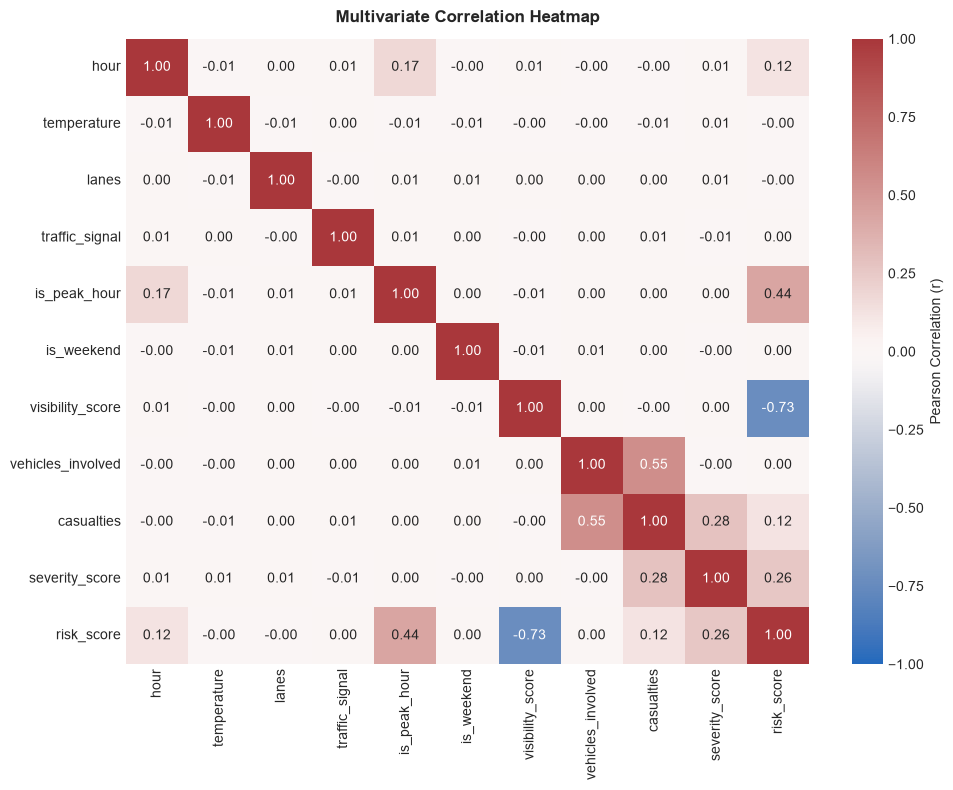

In [11]:
num_cols = ['hour', 'temperature', 'lanes', 'traffic_signal', 'is_peak_hour', 'is_weekend', 'visibility_score', 'vehicles_involved', 'casualties', 'severity_score', 'risk_score']
corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title('Multivariate Correlation Heatmap', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


### STEP 4.20: Automated EDA Summary

In [12]:
print("="*60)
print("URBANFLOW AUTOMATED EDA SUMMARY")
print("="*60)
print(f"Overall Total Collisions:   {len(df):,}")
print(f"Total Casualties:          {int(df['casualties'].sum()):,}")
print(f"Overall Mean Risk Score:   {df['risk_score'].mean():.4f}")
print(f"Highest Accident Month:    {df['month_name'].value_counts().index[0]} ({df['month_name'].value_counts().iloc[0]:,} crashes)")
print(f"Highest Accident Hour:     {df['hour'].value_counts().index[0]}:00 ({df['hour'].value_counts().iloc[0]:,} crashes)")
print(f"Most Frequent Severity:    Minor ({df['accident_severity'].value_counts()['minor']:,} crashes, 55.1%)")
print(f"Most Severe Category Risk: Fatal Collisions (Mean Risk = 0.6075)")
print(f"Leading Collision Cause:   Distraction ({df['cause'].value_counts()['distraction']:,} crashes)")
print(f"City with Most Collisions: Chandigarh ({df['city'].value_counts()['chandigarh']:,} crashes)")
print(f"City with Highest Risk:    Chandigarh (Mean Risk = 0.4416)")
print(f"Weather with Highest Risk: Dense Fog (Mean Risk = 0.5891)")
print(f"High-Risk Collisions:      {len(df[df['risk_category'] == 'High Risk']):,} crashes (24.1%)")
print("="*60)


URBANFLOW AUTOMATED EDA SUMMARY
Overall Total Collisions:   20,000
Total Casualties:          34,529
Overall Mean Risk Score:   0.4376
Highest Accident Month:    January (2,044 crashes)
Highest Accident Hour:     2:00 (888 crashes)
Most Frequent Severity:    Minor (11,025 crashes, 55.1%)
Most Severe Category Risk: Fatal Collisions (Mean Risk = 0.6075)
Leading Collision Cause:   Distraction (4,026 crashes)
City with Most Collisions: Chandigarh (2,577 crashes)
City with Highest Risk:    Chandigarh (Mean Risk = 0.4416)
Weather with Highest Risk: Dense Fog (Mean Risk = 0.5891)
High-Risk Collisions:      4,810 crashes (24.1%)
